In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np 
import cftime

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + 20, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [3]:
#here we focus on the asymmetric baseline simulation
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/falwa_output/

years_range = range(13, 121)
files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in years_range]

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/falwa_output


In [4]:
ds = xr.open_mfdataset(files_falwa,combine='nested',concat_dim='time',parallel=True, chunks={'time': 1000})

ds = flip_and_append(ds)

In [8]:
#here we focus on the asymmetric baseline simulation
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/falwa_output/

years_range = range(13, 121)
files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in years_range]

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/falwa_output


In [9]:
ds_base = xr.open_mfdataset(files_falwa,combine='nested',concat_dim='time',parallel=True, chunks={'time': 1000})

ds_base = flip_and_append(ds_base)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

A = ds['dw_lwa'].loc[:,30,:].values.flatten()#mean(dim=['lon','lat'])

B = (ds['u_baro']).loc[:,30,:].values.flatten()#mean(dim=['lon','lat'])

print(A.shape,B.shape)

# Convert xarray DataArrays to DataFrame
df = pd.DataFrame({'A': A, 'B': B})

# Bin A into 15 equal-width intervals
df['A_binned'] = pd.cut(df['A'], bins=20)

# Group by A_binned
grouped = df.groupby('A_binned')

# Plot boxplots of B for each A bin
fig, ax = plt.subplots(figsize=(5, 5))
grouped.boxplot(column='B', subplots=False, ax=ax, rot=45,  showfliers=False)

ax.set_ylabel(r'Binned U')
ax.set_xlabel(r'Acos$\phi$ distribution')
plt.grid(True)
plt.tight_layout()
plt.show()

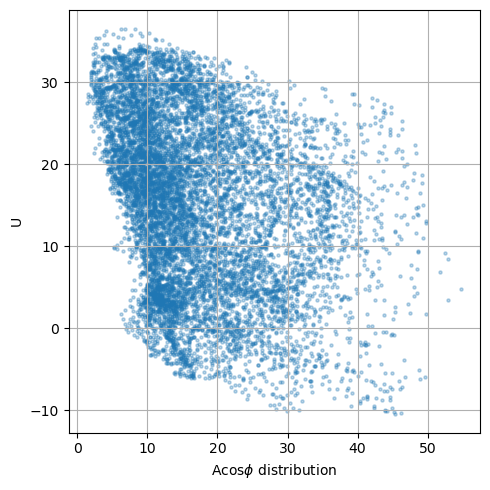

In [22]:
A = ds['dw_lwa'].loc[:,30:70,:].values.flatten()[:10000]
B = ds['u_baro'].loc[:,30:70,:].values.flatten()[:10000]

plt.figure(figsize=(5, 5))
plt.scatter(A, B, alpha=0.3, s=5)
plt.xlabel(r'Acos$\phi$ distribution')
plt.ylabel(r'U')
plt.grid(True)
plt.tight_layout()
plt.show()

11.981262051985194


Text(0, 0.5, 'counts')

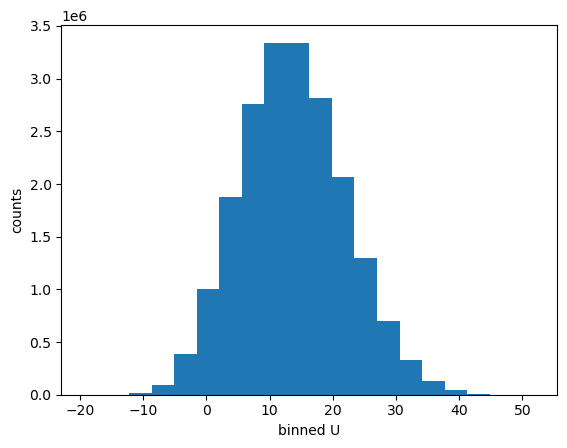

In [18]:
print(np.mean(A))

plt.hist(B,bins=20)
#plt.vlines(43,0,1.2e7,color='black',label='empirical maximum LWA')
#plt.vlines(percentile,0,1.2e7,color='orange',label='85th percentile')
#plt.legend()
plt.xlabel(r'binned U')
plt.ylabel(r'counts')

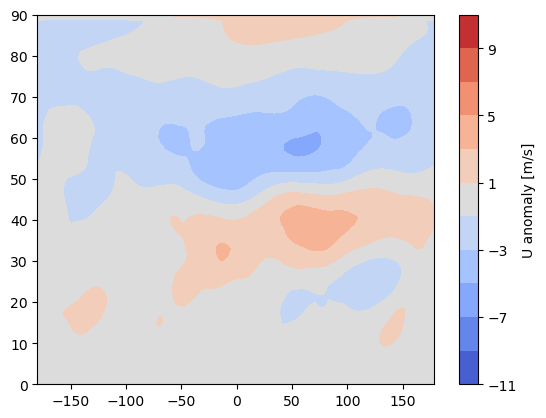

In [13]:
plt.contourf(ds['lon'],ds['lat'],ds['u_baro'][:1000].mean('time')-ds_base['u_baro'][:1000].mean('time'),levels = np.arange(-11,12,2),cmap='coolwarm')
plt.colorbar(label='U anomaly [m/s]')